First Five Records:
     Month  Passengers
0  1949-01         112
1  1949-02         118
2  1949-03         132
3  1949-04         129
4  1949-05         121

Dataset Shape: (144, 2)

Missing Values:
Passengers    0
dtype: int64


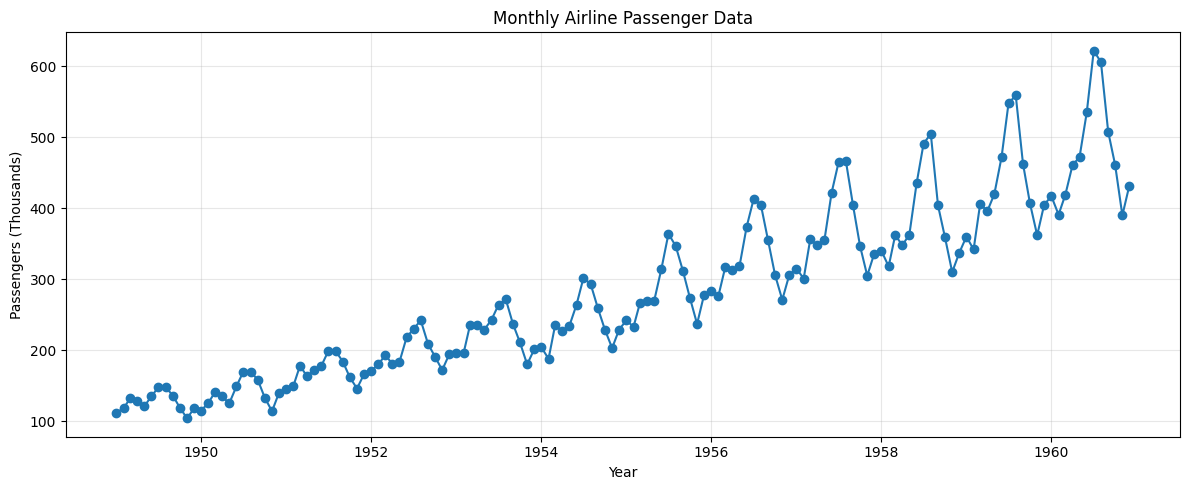

Training Samples: 132
Testing Samples: 12

SARIMA Model Summary:
                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  132
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -396.681
Date:                            Mon, 26 Oct 2026   AIC                            803.363
Time:                                    17:11:29   BIC                            816.633
Sample:                                01-01-1949   HQIC                           808.740
                                     - 12-01-1959                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5400      0.338     -1.596      

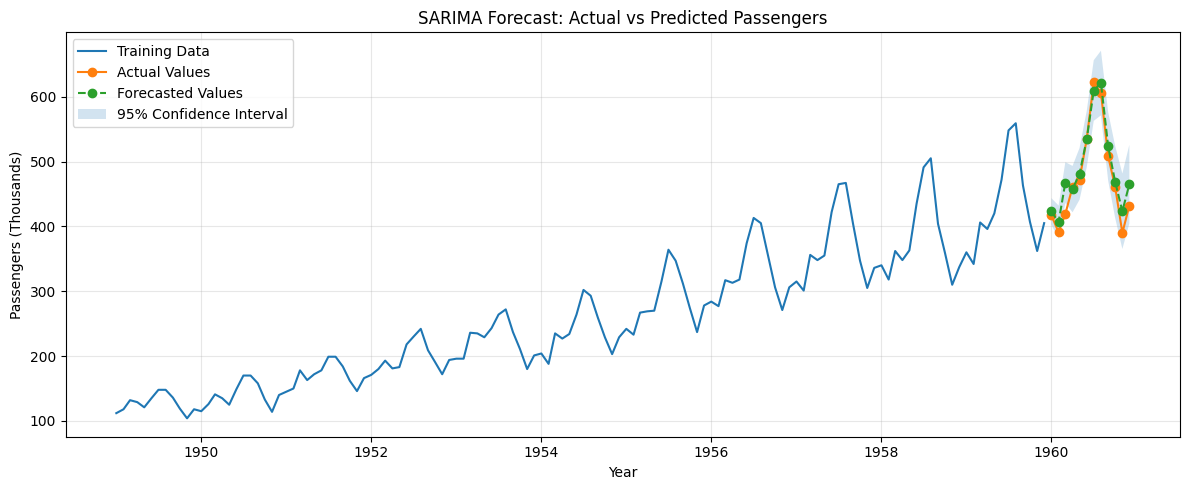

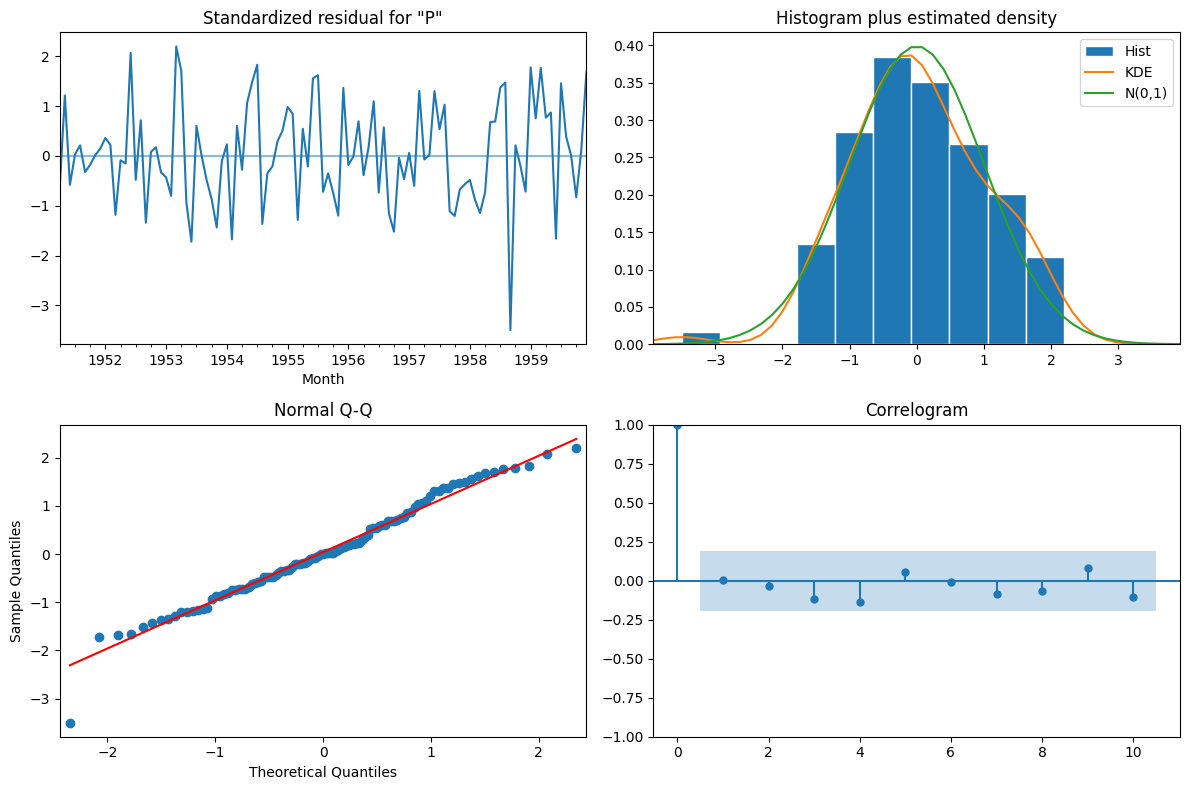

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
data = pd.read_csv(url)
print("First Five Records:")
print(data.head())
print("\nDataset Shape:", data.shape)

data["Month"] = pd.to_datetime(data["Month"])
data = data.set_index("Month").asfreq("MS")

print("\nMissing Values:")
print(data.isnull().sum())

plt.figure(figsize=(12, 5))
plt.plot(data.index, data["Passengers"], marker="o")
plt.title("Monthly Airline Passenger Data")
plt.xlabel("Year")
plt.ylabel("Passengers (Thousands)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

train = data.iloc[:-12]
test = data.iloc[-12:]

print("Training Samples:", len(train))
print("Testing Samples:", len(test))

model = SARIMAX(
    train["Passengers"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False)

results = model.fit(disp=False)

print("\nSARIMA Model Summary:")
print(results.summary())

forecast_result = results.get_forecast(steps=len(test))
predicted = forecast_result.predicted_mean
confidence = forecast_result.conf_int()

comparison = pd.DataFrame({
    "Actual": test["Passengers"].values,
    "Predicted": predicted.values,
    "Lower Bound": confidence.iloc[:, 0].values,
    "Upper Bound": confidence.iloc[:, 1].values}, index=test.index)

print("\nActual vs Predicted Passenger Counts:")
print(comparison.round(2))

mae = mean_absolute_error(
    comparison["Actual"], comparison["Predicted"])
rmse = np.sqrt(mean_squared_error(
    comparison["Actual"], comparison["Predicted"]))

print("\nModel Evaluation:")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))

plt.figure(figsize=(12, 5))
plt.plot(train.index, train["Passengers"], label="Training Data")
plt.plot(test.index, test["Passengers"], marker="o", label="Actual Values")
plt.plot(test.index, predicted.values, marker="o", linestyle="--", label="Forecasted Values")
plt.fill_between(
    test.index,
    confidence.iloc[:, 0].values,
    confidence.iloc[:, 1].values,
    alpha=0.2,
    label="95% Confidence Interval")
plt.title("SARIMA Forecast: Actual vs Predicted Passengers")
plt.xlabel("Year")
plt.ylabel("Passengers (Thousands)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
results.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()